# 02: Monthly indicators

Collects monthly indicators for the nowcast from Jan 2014 to the latest month available, and aggregates them to calendar quarters.

**Rules**
- Every value is parsed from a downloaded file, and its URL is recorded. Nothing is typed in by hand.
- Gaps stay blank. They appear as blank rows in the monthly file and in the data gaps cell at the end.
- Each base year is a separate series (`..._base2011`), so nothing is spliced and no YoY crosses a base change.
- `vintage` is `first` for the earliest published value found and `latest` for the current official series.

**Files written**
- `indicators_monthly.csv`: the requested columns, in long format.
- `indicators_quarterly.csv`: quarterly values and YoY, with a `complete` flag.
- `indicators_coverage.csv`: the coverage and lag table.
- `indicators_provenance.csv`: how each release date was obtained.

**Fetching:** files are downloaded with curl, because Python's bundled certificates reject two of the government hosts. Certificate checks stay on.


In [1]:
import calendar, html, json, os, re, subprocess, time, urllib.parse as up, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pdfplumber
from IPython.display import display

warnings.filterwarnings("ignore", message=".*xlrd.*")
# NOWCAST_RAW lets a reproducibility run start from an empty folder without touching the usual one.
RAW = Path(os.environ.get("NOWCAST_RAW", "../data/raw/indicators")); RAW.mkdir(parents=True, exist_ok=True)
PROCESSED = Path("../data/processed"); REPORTS = Path("../reports")
START, END = pd.Period("2014-01", "M"), pd.Period("2026-10", "M")
UA = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120 Safari/537.36"
MONTHS = {m.lower(): i for i, m in enumerate(calendar.month_name) if m}
MON3 = {m.lower(): i for i, m in enumerate(calendar.month_abbr) if m}
MONTH_RE = "|".join(calendar.month_name[1:])

def fetch(url, path, data=None, timeout=90):
    # curl, because Python's bundled certificates reject eaindustry.nic.in and api.mospi.gov.in;
    # curl uses the Windows store with verification on. Results are cached, failures are not.
    path = Path(path)
    if path.exists() and path.stat().st_size > 0:
        return True
    cmd = ["curl", "-sL", "-A", UA, "--max-time", str(timeout), "-o", str(path), "-w", "%{http_code}"]
    if data:
        cmd += ["--data-binary", "@-", "-H", "Content-Type: application/x-www-form-urlencoded"]
    # Wayback and PIB drop requests when busy, so give them a few tries with a pause before counting a file as missing.
    busy = "web.archive.org" in url or "pib.gov.in" in url
    for attempt in range(4 if busy else 1):
        out = subprocess.run(cmd + [url], capture_output=True, input=data.encode() if data else None)
        if out.stdout.decode().strip() == "200":
            Path(f"{path}.url").write_text(url, encoding="utf8")    # the true source, for cached reruns
            return True
        path.unlink(missing_ok=True)
        time.sleep(5 * (attempt + 1) if busy else 0)
    return False

def cached_source(path):
    # The URL a cached file really came from, when several candidates were possible.
    sidecar = Path(f"{path}.url")
    return sidecar.read_text(encoding="utf8") if Path(path).exists() and sidecar.exists() else None

def fetch_all(jobs, workers=8):
    # jobs: (url, path) pairs
    with ThreadPoolExecutor(workers) as pool:
        return list(pool.map(lambda j: fetch(*j), jobs))

def is_pdf(path):
    path = Path(path)
    return path.exists() and path.read_bytes()[:4] == b"%PDF"

def pdf_pages(path):
    try:
        with pdfplumber.open(path) as pdf:
            return [re.sub(r"[ \t]+", " ", page.extract_text() or "") for page in pdf.pages], pdf.metadata or {}
    except Exception as err:
        # A truncated download: drop it from the cache so a rerun fetches it again, and count it as a failure.
        print("unreadable, removed from cache:", Path(path).name, type(err).__name__)
        Path(path).unlink(missing_ok=True)
        return [], {}

def squash(text):
    return re.sub(r"\s+", " ", text)

def meta_date(meta):
    m = re.match(r"D:(\d{4})(\d{2})(\d{2})", str(meta.get("CreationDate", "")))
    return pd.Timestamp(f"{m[1]}-{m[2]}-{m[3]}") if m else pd.NaT

def cdx(url, pattern=None, limit=4000):
    # Wayback's index, cached so that reruns use the same file list.
    name = RAW / ("cdx_" + re.sub(r"\W+", "_", url) + ".txt")
    fetch(f"https://web.archive.org/cdx/search/cdx?url={up.quote(url, safe='/*:')}&output=txt&fl=timestamp,original"
          f"&collapse=urlkey&filter=statuscode:200&limit={limit}", name, timeout=170)
    lines = name.read_text("utf8", "ignore").splitlines() if name.exists() else []
    rows = [l.split(" ", 1) for l in lines if " " in l]
    return [(t, u) for t, u in rows if not pattern or re.search(pattern, u, re.I)]

records, method_notes = [], {}

def add(indicator, ref_month, value, unit, release_date, vintage, source_url, date_method=""):
    records.append(dict(indicator=indicator, ref_month=str(ref_month), value=value, unit=unit,
                        release_date=release_date, vintage=vintage, source_url=source_url, date_method=date_method))

## 1. IIP

In [2]:
IIP_API = "https://api.mospi.gov.in/api/iip/getIIPMonthly"
for base, tag in (("2011-12", "2011"), ("2022-23", "2022")):
    url = f"{IIP_API}?base_year={base}&type=General&limit=200"
    path = RAW / f"iip_api_{tag}.json"
    if fetch(url, path):
        for row in json.loads(path.read_text("utf8"))["data"]:
            if row["category"] == "General":
                ref = pd.Period(f"{row['year']}-{MONTHS[row['month'].lower()]:02d}", "M")
                if ref >= START:
                    add(f"iip_general_base{tag}", ref, float(row["index"]), "index", pd.NaT, "latest", url)

iip_files = {u.split("?")[0]: t for host in ("mospi.gov.in", "mospi.nic.in")
             for t, u in cdx(f"{host}/sites/default/files/press_release/*", r"iip.*\.pdf$")
             if not re.search(r"/(h_|hindi)|hindi|corrigendum", u, re.I)}
def iip_job(item):
    url, stamp = item
    name = re.sub(r"\W+", "_", url.split("/")[-1])[:90] + ".pdf"
    path = RAW / "iip" / name
    path.parent.mkdir(exist_ok=True)
    live = url.replace("http://", "https://").replace(":80/", "/")
    if cached_source(path):
        return cached_source(path), path
    return live if fetch(live, path) else (f"https://web.archive.org/web/{stamp}id_/{url}" if fetch(f"https://web.archive.org/web/{stamp}id_/{url}", path) else None), path
with ThreadPoolExecutor(8) as pool:
    iip_got = list(pool.map(iip_job, iip_files.items()))

IIP_PAT = [
    rf"(?:Index of Industrial Production|IIP)[^.]{{0,140}}?(?:for|in|of)(?: the month of)?\s*({MONTH_RE})[ ,']*(\d{{4}})[^.]{{0,90}}?(?:stands? at|stood at|at)\s*(\d{{2,3}}\.\d)",
    rf"General (?:Index|index)[^.]{{0,80}}?(?:for|in)(?: the month of)?\s*({MONTH_RE})[ ,']*(\d{{4}})[^.]{{0,90}}?(?:stands? at|stood at|at)\s*(\d{{2,3}}\.\d)",
    rf"({MONTH_RE})[ ,']*(\d{{4}})[^.]{{0,60}}?General[^.]{{0,60}}?(?:stands? at|stood at|is)\s*(\d{{2,3}}\.\d)",
]
iip_rows, iip_fail = [], []
for url, path in iip_got:
    if url is None or not is_pdf(path):
        continue
    pages, meta = pdf_pages(path)
    text = squash(" ".join(pages[:3]))
    hit = next((m for p in IIP_PAT for m in [re.search(p, text)] if m), None)
    if hit:
        ref_month, ref_year, value = hit[1], hit[2], hit[3]
    else:
        # From 2020 the month and the index sit in separate clauses.
        level = re.search(r"Quick Estimates? of (?:Index of Industrial Production \(IIP\)|IIP)[^.]{0,40}?stands? at\s*(\d{2,3}\.\d)", text)
        month = re.search(rf"[Ff]or the month of\s*({MONTH_RE})[ ,']*(\d{{4}})", text)
        if not level or not month:
            iip_fail.append(path.name); continue
        ref_month, ref_year, value = month[1], month[2], level[1]
    base = re.search(r"(?:[Bb]ase|BASE)\s*(?:[Yy]ear)?[^0-9]{0,15}(2004-05|2011-12|2022-23)", " ".join(pages)) or re.search(r"(2022-23|2011-12|2004-05)\s*=\s*100", " ".join(pages))
    ref = pd.Period(f"{ref_year}-{MONTHS[ref_month.lower()]:02d}", "M")
    base_inferred = not base
    if base_inferred and not pd.Period("2017-04", "M") <= ref <= pd.Period("2025-09", "M"):
        iip_fail.append(path.name + " (no base)"); continue
    released = (re.search(rf"(\d{{1,2}})\s*(?:st|nd|rd|th)?\s*({MONTH_RE}),?\s*(\d{{4}})", text[:600])
                or re.search(rf"()({MONTH_RE})\s*(\d{{1,2}})(?:st|nd|rd|th)?,\s*(\d{{4}})", text[:600]))
    if released and released[1] == "":
        date = pd.to_datetime(f"{released[3]} {released[2]} {released[4]}", format="%d %B %Y", errors="coerce")
    else:
        date = pd.to_datetime(f"{released[1]} {released[2]} {released[3]}", format="%d %B %Y", errors="coerce") if released else pd.NaT
    iip_rows.append(dict(ref=ref, value=float(value), base=base[1] if base else "2011-12", url=url, date=date if pd.notna(date) else meta_date(meta),
                         method=("press note" if pd.notna(date) else "pdf_created") + ("; base inferred" if base_inferred else "")))
iip_first = pd.DataFrame(iip_rows)
if len(iip_first):
    iip_first = iip_first[iip_first["ref"] >= START].sort_values(["ref", "date"]).drop_duplicates("ref")
    for r in iip_first.itertuples():
        add(f"iip_general_base{r.base[:4]}", r.ref, r.value, "index", r.date, "first", r.url, r.method)
print(f"IIP files {len(iip_got)}, parsed {len(iip_rows)}, failed {len(iip_fail)}: {iip_fail[:25]}")
print(iip_first.groupby("base")["ref"].agg(["min", "max", "count"]).to_string() if len(iip_first) else "none")

unreadable, removed from cache: IIP_20Nov_2720_20Press_20Release_Approved_20_pdf.pdf PdfminerException


IIP files 215, parsed 206, failed 9: ['IIP_20Dec_23_20Press_20Release_pdf.pdf', 'IIP_20Jan_2724_20Press_20Release_pdf.pdf', 'IIP_20Nov_2723_20Press_20Release_pdf.pdf', 'IIP_20press_20release_20October18_pdf.pdf', 'iip_PR_12may17_pdf.pdf', 'NEW_timeline_IIP_press_release_17_04_25_pdf.pdf', 'IIP_20Nov_2720_20Press_20Release_Approved_20_pdf.pdf', 'IIP_20press_20release_20October18_pdf.pdf', 'iip_PR_12may17_pdf.pdf']
             min      max  count
base                            
2004-05  2014-02  2017-02     36
2011-12  2017-04  2025-09     94


## 2. Eight core industries

In [3]:
EA = "https://eaindustry.nic.in/"
core_ok = {}
for fname, tag, skip in (("Core Industries 2004-05.xlsx", "2004", 0), ("Core_Industries_2011_12_20260720.xlsx", "2011", 0), ("Core_Industries_2022_23_20261021.xlsx", "2022", 0)):
    url = EA + "eight_core_infra/" + up.quote(fname)
    path = RAW / f"core_{tag}.xlsx"
    if not fetch(url, path):
        continue
    df = pd.read_excel(path, sheet_name="Index", header=None)
    head = next(i for i in range(6) if str(df.iat[i, 0]).strip().startswith("Months"))
    cols = [str(c).lower() for c in df.iloc[head]]
    overall = next(i for i, c in enumerate(cols) if "overall" in c)
    electric = next(i for i, c in enumerate(cols) if "electric" in c)
    for row in df.iloc[head + 1:].itertuples(index=False):
        raw_month = row[0]
        if isinstance(raw_month, str) and not re.fullmatch(r"[A-Za-z]{3}-\d{2}", raw_month.strip()):
            continue
        ref = pd.Period(pd.to_datetime(raw_month, format="%b-%y") if isinstance(raw_month, str) else raw_month, "M")
        if START <= ref and pd.notna(row[overall]):
            add(f"core8_overall_base{tag}", ref, round(float(row[overall]), 2), "index", pd.NaT, "latest", url)
            add(f"electricity_core_index_base{tag}", ref, round(float(row[electric]), 2), "index", pd.NaT, "latest", url)

def core_job(period):
    url = f"{EA}archive_data/ici_press_release/IPR_{period.year}_{period.month:02d}.pdf"
    path = RAW / "core" / f"IPR_{period.year}_{period.month:02d}.pdf"
    path.parent.mkdir(exist_ok=True)
    return period, url, path, fetch(url, path)
with ThreadPoolExecutor(8) as pool:
    core_got = list(pool.map(core_job, pd.period_range(START, "2026-08", freq="M")))
late = RAW / "core" / "IPR_2026_09.pdf"
if fetch(EA + "eight_core_infra/Press_Release_ICI_20261021.pdf", late):
    core_got.append((pd.Period("2026-09", "M"), EA + "eight_core_infra/Press_Release_ICI_20261021.pdf", late, True))

core_fail, core_dates, core_quoted = [], {}, {}
for period, url, path, ok in core_got:
    if not ok or not is_pdf(path):
        core_fail.append(str(period)); continue
    pages, meta = pdf_pages(path)
    text = squash(" ".join(pages))
    month = calendar.month_name[period.month]
    hits = [re.search(rf"(?:stands?|stood|was|is)\s*(?:at)?\s*(\d{{2,3}}\.\d)\s*(?:\(?Provisional\)?)?\s*(?:in|for|during)\s*(?:the month of\s*)?{month}", text, re.I),
            re.search(rf"[Ii]ndex[^.]{{0,160}}?{month}[ ,]*(?:{period.year})?[^.]{{0,70}}?(?:stands?|stood|was|is|at)\s*(?:at)?\s*(\d{{2,3}}\.\d)", text),
            re.search(rf"Overall Index[^0-9]{{0,40}}(?:\d[\d.]* ){{0,14}}?(\d{{2,3}}\.\d)\*?\s*$", text)]
    table = next((re.findall(r"-?\d+\.\d+", line) for page in pages for line in page.split("\n")
                  if re.match(r"(Overall|Combined|ICI|General)\b.*Index|Overall Index|Overall", line.strip()) and len(re.findall(r"\d+\.\d+", line)) >= 6), None)
    value = next((float(h[1]) for h in hits[:2] if h), None)
    if value is None:
        # Annex II: the first row for the month is the index table, and its last column is the overall index.
        label = f"{period.strftime('%b')}-{str(period.year)[-2:]}"
        row = next((re.findall(r"-?\d+\.\d+", line) for page in pages for line in page.split("\n")
                    if re.match(rf"{label}\s*(?:\*|\(P\))?\s+\d", line.strip())), None)
        if row and len(row) >= 8:
            value = float(row[-1])
    base = re.search(r"base[^0-9]{0,20}(2004-05|2011-12|2022-23)", text, re.I)
    embargo = re.search(rf"till [^.]{{0,40}}?(\d{{1,2}})\s*(?:st|nd|rd|th)\s*({MONTH_RE}),?\s*(\d{{4}})", text[:400])
    date = pd.to_datetime(f"{embargo[1]} {embargo[2]} {embargo[3]}", format="%d %B %Y") if embargo else meta_date(meta)
    core_dates[period] = (date, url, "embargo line" if embargo else "pdf_created")
    quoted = re.search(rf"final index for the month of ({MONTH_RE}) (\d{{4}}) has been revised from (\d{{2,3}}\.\d)", text)
    if quoted:
        core_quoted[pd.Period(f"{quoted[2]}-{MONTHS[quoted[1].lower()]:02d}", "M")] = (float(quoted[3]), url, base[1] if base else None)
    if value is None or base is None:
        core_fail.append(f"{period}*"); continue
    add(f"core8_overall_base{base[1][:4]}", period, value, "index", date, "first", url, "embargo line" if embargo else "pdf_created")
# Later notes quote the provisional index of the month before, which is that month's first print.
already = {r["ref_month"] for r in records if r["indicator"].startswith("core8") and r["vintage"] == "first"}
for period, (value, url, base) in core_quoted.items():
    if str(period) not in already and base and period in core_dates:
        add(f"core8_overall_base{base[:4]}", period, value, "index", core_dates[period][0], "first", url, core_dates[period][2] + "; value quoted in next note")
        core_fail = [f for f in core_fail if f != f"{period}*"]
print("core releases", len(core_got), "still failed", core_fail)

core releases 153 still failed ['2014-03*', '2015-07*', '2016-05*', '2016-09*', '2016-12*', '2017-01*', '2017-02*', '2017-03*', '2017-04*', '2024-12*', '2026-09*']


## 3. Petroleum (PPAC)

In [4]:
ppac_files = {}
for fy in [f"{y}-{y + 1}" for y in range(2014, 2027)]:
    path = RAW / f"ppac_{fy}.json"
    url = "https://ppac.gov.in/AjaxController/getConsumptionPetroleumProductsData"
    if not fetch(url, path, data=f"financialYear={fy}&reportBy=1&pageId=43"):
        continue
    rows = json.loads(path.read_text("utf8"))["result"]
    for row in (rows.values() if isinstance(rows, dict) else rows):
        title = re.sub(r"<[^>]+>", "", str(row.get("title", ""))).strip().upper()
        name = {"MS": "petrol_ms_consumption", "PETROL": "petrol_ms_consumption", "MS (PETROL)": "petrol_ms_consumption",
                "HSD": "diesel_hsd_consumption", "DIESEL": "diesel_hsd_consumption", "HSDO": "diesel_hsd_consumption"}.get(title)
        if not name:
            continue
        start = int(fy[:4])
        for i, month in enumerate(("april", "may", "june", "july", "august", "september", "october", "november", "december", "january", "february", "march")):
            if row.get(month) not in ("", None):
                ref = pd.Period(f"{start + (i >= 9)}-{i + 4 if i < 9 else i - 8:02d}", "M")
                add(name, ref, float(str(row[month]).replace(",", "")), "000 tonnes", pd.NaT, "latest", row["file_name"].replace(" ", "%20"))
print("ppac rows", sum(r["indicator"].endswith("consumption") for r in records))


# Before Apr 2020 PPAC's data call returns nothing, so older months come from archived monthly Snapshot reports.
# They round to 0.1 million tonnes, so they stay in separate series rather than being joined to the figures above.
snapshots = [(t, u) for t, u in cdx("ppac.gov.in/WriteReadData/*") if re.search(r"(?i)snapshot.*\.pdf$", u)]
(RAW / "ppac").mkdir(exist_ok=True)
def snapshot_job(item):
    stamp, url = item
    path = RAW / "ppac" / (re.sub(r"\W+", "_", url.split("/")[-1])[-70:] + ".pdf")
    source = f"https://web.archive.org/web/{stamp}id_/{url}"
    # Wayback drops some requests when busy, so try again before counting a file as missing.
    return source, url, path, any(fetch(source, path, timeout=150) and is_pdf(path) for _ in range(3))
with ThreadPoolExecutor(2) as pool:
    snapshot_got = list(pool.map(snapshot_job, snapshots))
snap_rows, snap_fail = {}, []
for source, url, path, ok in snapshot_got:
    if not ok or not is_pdf(path):
        snap_fail.append(url.split("/")[-1][-40:]); continue
    pages, _ = pdf_pages(path)
    page = next((t for t in pages if re.search(r"(?i)production and consumption of petroleum products", t) and re.search(r"(?m)^HSD\s+\d", t)), "")
    table = page[re.search(r"(?i)production and consumption of petroleum products", page).start():] if page else ""
    # Headers vary: "Oct-2017 Oct-2018 (P)", "January 2015 January 2016 (P)". The same month two years running marks the columns.
    head = next((m for m in re.finditer(r"\b([A-Z][a-z]{2,8})[-' ]*(20\d{2}|\d{2})\s*(?:\(P\))?\s+([A-Z][a-z]{2,8})[-' ]*(20\d{2}|\d{2})", table)
                 if m[1][:3] == m[3][:3] and m[1][:3].lower() in MON3), None)
    if not head:
        snap_fail.append(url.split("/")[-1][-40:]); continue
    year = lambda y: int(y) if len(y) == 4 else 2000 + int(y)
    prior, current = (pd.Period(f"{year(head[g])}-{MON3[head[1][:3].lower()]:02d}", "M") for g in (2, 4))
    stamp = re.search(r"/(20\d{2})(\d{2})(\d{2})\d{6,}", url)
    date = pd.to_datetime(f"{stamp[1]}-{stamp[2]}-{stamp[3]}", errors="coerce") if stamp else pd.NaT
    for label, name in (("MS", "petrol_ms_consumption_snapshot"), ("HSD", "diesel_hsd_consumption_snapshot")):
        line = re.search(rf"(?m)^{label}\s+((?:-?\d+\.?\d*\s+){{9,}}-?\d+\.?\d*)", table)
        if line and (current - prior).n == 12:
            # Read from the right: the last eight numbers are the two months and two cumulative periods, each production then consumption.
            nums = [float(x) for x in line[1].split()]
            # A monthly figure outside these ranges means the row was read from the wrong columns.
            low, high = (1.0, 4.0) if label == "MS" else (3.0, 10.0)
            if not (low <= nums[-5] <= high and low <= nums[-7] <= high):
                snap_fail.append(url.split("/")[-1][-40:] + " (out of range)"); continue
            snap_rows.setdefault((name, current), (nums[-5], date, source, "first"))
            if (name, prior) not in snap_rows:
                snap_rows[(name, prior)] = (nums[-7], date, source, "latest")
for (name, ref), (val, date, source, vintage) in sorted(snap_rows.items()):
    if ref <= pd.Period("2020-03", "M"):
        add(name, ref, val, "million tonnes (1 dp)", date if vintage == "first" else pd.NaT, vintage, source, "upload stamp in file name" if vintage == "first" else "")
snapshot_check = pd.Series({k[1]: v[0] for k, v in snap_rows.items() if k[0].startswith("diesel") and k[1] >= pd.Period("2020-04", "M")})
exact = pd.DataFrame(records).query("indicator == 'diesel_hsd_consumption'").assign(ref=lambda d: pd.PeriodIndex(d["ref_month"], freq="M")).set_index("ref")["value"] / 1000
gap = (snapshot_check - exact.reindex(snapshot_check.index)).abs().dropna()
print(f"snapshot files {len(snapshots)}, unparsed {len(snap_fail)}; months to Mar 2020:", sum(k[1] <= pd.Period("2020-03", "M") for k in snap_rows) // 2)
print(f"diesel, snapshot vs exact series from Apr 2020: {len(gap)} months, median gap {gap.median():.3f}, largest {gap.max():.3f} million tonnes")
print("unparsed snapshots:", snap_fail)

ppac rows 156


unreadable, removed from cache: 097SnapshotofIndia_E2_80_99sOil_Gasdata_July2020_Revised16_09_2020_pdf.pdf PdfminerException
unreadable, removed from cache: 872SnapshotofIndia_E2_80_99sOil_Gasdata_July2020_Revised16_09_2020_pdf.pdf PdfminerException


unreadable, removed from cache: 0200623267188328SnapshotofIndia_E2_80_99sOil_Gasdata_September2020_pdf.pdf PdfminerException
unreadable, removed from cache: 202011250837320964543SnapshotofIndiasOilGasdataOctober2020_revised_pdf.pdf PdfminerException


unreadable, removed from cache: 202101201251225115662SnapshotofIndiasOilGasdata_December2020_RV_pdf.pdf PdfminerException


unreadable, removed from cache: 202104200335114519410SnapshotofIndiasOilGasdataMarch2021_pdf.pdf PdfminerException
unreadable, removed from cache: 202104220520386898857SnapshotofIndiasOilGasdataMarch2021_rv_pdf.pdf PdfminerException


unreadable, removed from cache: 202201220933119577745SnapshotofIndiasOilandGasdataDecember2021_pdf.pdf PdfminerException


unreadable, removed from cache: 202209160807210018941SnapshotofIndiasOilandGasdataAug2022upload_pdf.pdf PdfminerException
unreadable, removed from cache: 202209160814121551672SnapshotofIndiasOilandGasdataAug2022upload_pdf.pdf PdfminerException


unreadable, removed from cache: Snapshot_20of_20India_s_20Oil_20Gas_20data_20January_202021_pdf.pdf PdfminerException
unreadable, removed from cache: Snapshot_20of_20Indias_20Oil_20_20Gas_20data_20November_202020_Rv_pdf.pdf PdfminerException
unreadable, removed from cache: Snapshot_20of_20Indias_20Oil_20and_20Gas_20data_20June_202021_pdf.pdf PdfminerException


unreadable, removed from cache: Snapshot_20of_20Indias_20Oil_20Gas_20data_20March_202021_rv_pdf.pdf PdfminerException
snapshot files 64, unparsed 26; months to Mar 2020: 24
diesel, snapshot vs exact series from Apr 2020: 25 months, median gap 0.013, largest 0.047 million tonnes
unparsed snapshots: ['1409231239065062686Snapshot_IOGD_MAR.pdf', '1409231240448732870Snapshot_IOGD_JUN.pdf', "napshotofIndia'sOil&Gasdata-July2016.pdf", 'SnapshotofIndiasOilGasdata,April2020.pdf (out of range)', 'SnapshotofIndiasOilGasdata,April2020.pdf (out of range)', 'l&Gasdata,July2020-Revised16.09.2020.pdf', 'l&Gasdata,July2020-Revised16.09.2020.pdf', 'a%E2%80%99sOil&Gasdata,September2020.pdf', 'fIndiasOilGasdataOctober2020-revised.pdf', 'otofIndiasOilGasdata,December2020-RV.pdf', '0SnapshotofIndiasOilGasdataMarch2021.pdf', 'apshotofIndiasOilGasdataMarch2021_rv.pdf', 'SnapshotofIndiasOil&GasdataApril2021.pdf (out of range)', 'SnapshotofIndiasOil&GasdataApril2021.pdf (out of range)', 'hotofIndiasOilandGasdat

## 4. Electricity (CEA via National Power Portal)

In [5]:
def npp_job(args):
    period, kind = args
    mon = period.strftime("%b").upper()
    url = f"https://npp.gov.in/public-reports/cea/monthly/generation/18_col_{kind}/{period.year}/{mon}/18_col_{kind}-1_{period.year}-{mon}.xls"
    path = RAW / "npp" / f"{kind}_{period}.xls"
    path.parent.mkdir(exist_ok=True)
    return period, kind, url, path, fetch(url, path)
with ThreadPoolExecutor(8) as pool:
    npp_got = list(pool.map(npp_job, [(p, k) for p in pd.period_range(START, "2026-09", freq="M") for k in ("act", "ten")]))
npp_rows = []
for period, kind, url, path, ok in npp_got:
    if not ok:
        continue
    try:
        df = pd.read_excel(path, header=None)
    except Exception:
        continue
    head = next((i for i in range(len(df)) if "ACTUAL" in " ".join(map(str, df.iloc[i].values))), None)
    col = next(j for j, v in enumerate(df.iloc[head].values) if str(v).strip().startswith("ACTUAL")) if head is not None else None
    total = next((row for row in df.values if re.fullmatch(r"(grand )?total|all india", str(row[0]).strip(), re.I)), None) if col is not None else None
    if total is None:
        total = next((row for row in df.values if any(re.fullmatch(r"(grand )?total|all india|total.*", str(v).strip(), re.I) for v in row[:3])), None)
    if total is not None and pd.notna(total[col]):
        npp_rows.append((period, kind, float(total[col]), url))
for period, kind, value, url in npp_rows:
    add("electricity_generation_cea", period, value, "GWh", pd.NaT, "first" if kind == "ten" else "latest", url)
print("npp files", sum(j[4] for j in npp_got), "rows", len(npp_rows), pd.Series([k for _, k, _, _ in npp_rows]).value_counts().to_dict())

npp files 174 rows 174 {'ten': 87, 'act': 87}


## 5. PIB release index

In [6]:
PIB = "https://www.pib.gov.in/allRel.aspx?reg=3&lang=1"
fetch(PIB, RAW / "pib_home.html")
home = (RAW / "pib_home.html").read_text("utf8", "ignore")
hidden = {m[0]: html.unescape(m[1]) for m in re.findall(r'<input type="hidden" name="([^"]+)"[^>]*value="([^"]*)"', home)}
MINISTRIES = {"railways": "23", "commerce": "16", "finance": "15"}
def pib_month(args):
    key, period = args
    form = dict(hidden); prefix = "ctl00$ContentPlaceHolder1$ddl"
    form.update({prefix + "Ministry": MINISTRIES[key], prefix + "day": "0", prefix + "Month": str(period.month), prefix + "Year": str(period.year)})
    path = RAW / "pib" / f"list_{key}_{period}.html"
    path.parent.mkdir(exist_ok=True)
    fetch(PIB, path, data=up.urlencode(form))
    text = path.read_text("utf8", "ignore") if path.exists() else ""
    return [(key, m[0], squash(html.unescape(m[1])).strip()) for m in re.findall(r'PRID=(\d+)[^>]*>\s*(?:<[^>]+>\s*)*([^<]{10,240})', text)]
with ThreadPoolExecutor(6) as pool:
    pib_index = pd.DataFrame([x for rows in pool.map(pib_month, [(k, p) for k in MINISTRIES for p in pd.period_range("2017-01", "2026-10", freq="M")]) for x in rows],
                             columns=["ministry", "prid", "title"]).drop_duplicates("prid")
print(pib_index.groupby("ministry").size().to_dict())

def pib_release(prid):
    path = RAW / "pib" / f"pr_{prid}.html"
    url = f"https://www.pib.gov.in/PressReleasePage.aspx?PRID={prid}"
    if not fetch(url, path):
        return None
    raw = path.read_text("utf8", "ignore")
    body = squash(html.unescape(re.sub(r"<(script|style)[\s\S]*?</\1>|<[^>]+>", " ", raw)))
    posted = re.search(r"Posted On:?\s*(\d{1,2})\s*([A-Za-z]{3})\s*(\d{4})", body)
    date = pd.to_datetime(f"{posted[1]} {posted[2]} {posted[3]}", format="%d %b %Y", errors="coerce") if posted else pd.NaT
    return dict(prid=prid, url=url, body=body, date=date)

def releases(mask):
    wanted = pib_index[mask]["prid"]
    with ThreadPoolExecutor(3) as pool:
        got = [r for r in pool.map(pib_release, wanted) if r]
    print(f"PIB pages: {len(got)} of {len(wanted)} retrieved")
    return got

{'commerce': 4277, 'finance': 5969, 'railways': 2781}


## 6. Rail freight

In [7]:
rail = releases(pib_index["ministry"].eq("railways") & pib_index["title"].str.contains(r"freight|loading|\bMT\b", case=False))
rail_rows = {}
RAIL_PATS = [rf"(?:during|in|for) (?:the month of )?({MONTH_RE})[ ,']*(\d{{4}})[^.]{{0,70}}?(?:freight )?(?:loading|loaded)[^.]{{0,40}}?(\d{{2,3}}(?:\.\d+)?)\s*(?:million tonnes|MT|million tons)",
             rf"(?:loaded|loading of|loading was|carried)[^.]{{0,40}}?(\d{{2,3}}(?:\.\d+)?)\s*(?:million tonnes|MT|million tons)[^.]{{0,40}}?(?:during|in|for) (?:the month of )?({MONTH_RE})[ ,']*(\d{{4}})"]
for r in sorted(rail, key=lambda r: (pd.isna(r["date"]), r["date"])):
    for i, pat in enumerate(RAIL_PATS):
        for m in re.finditer(pat, r["body"], re.I):
            mon, yr, val = (m[1], m[2], m[3]) if i == 0 else (m[2], m[3], m[1])
            ref = pd.Period(f"{yr}-{MONTHS[mon.lower()]:02d}", "M")
            # The release must come after the month it reports; this also drops prior-year comparisons.
            if 60 <= float(val) <= 220 and pd.notna(r["date"]) and ref < r["date"].to_period("M") and (r["date"].to_period("M") - ref).n <= 2 and ref not in rail_rows:
                rail_rows[ref] = (float(val), r["date"], r["url"], m[0][:150])
for ref, (val, date, url, _) in sorted(rail_rows.items()):
    add("rail_freight_loading", ref, val, "million tonnes", date, "first", url, "PIB posted date")
print("rail releases", len(rail), "months", len(rail_rows), min(rail_rows, default=None), max(rail_rows, default=None))

# No monthly release exists before mid-2020, but later releases quote earlier months as comparisons.
# These aren't first prints. Sentences about part of a month, one commodity or a cumulative total are skipped.
quoted_rail = {}
for r in sorted(rail, key=lambda r: (pd.isna(r["date"]), r["date"])):
    for pat, order in ((rf"(\d{{2,3}}(?:\.\d+)?)\s*(?:MT|[Mm]illion [Tt]onnes)\s*(?:\w+\s){{0,2}}in\s*({MONTH_RE})[ ,]*(20[12]\d)", (1, 2, 3)),
                       (rf"({MONTH_RE})[ ,]*(20[12]\d)\s*\((\d{{2,3}}(?:\.\d+)?)\s*(?:MT|[Mm]illion [Tt]onnes)\)", (3, 1, 2))):
        for m in re.finditer(pat, r["body"]):
            val, mon, yr = (m[i] for i in order)
            ref = pd.Period(f"{yr}-{MONTHS[mon.lower()]:02d}", "M")
            context = r["body"][max(0, m.start() - 130):m.end() + 20]
            if ref < pd.Period("2020-08", "M") and ref not in rail_rows and 55 <= float(val) <= 160 and not re.search(r"(?i)essential|coal|commodit|cumulative|\btill\b|from 1st|same date|week", context):
                quoted_rail[ref] = (float(val), r["url"], m[0][:90])
for ref, (val, url, _) in sorted(quoted_rail.items()):
    add("rail_freight_loading", ref, val, "million tonnes", pd.NaT, "latest", url)
print("rail months quoted in later releases:", {str(k): v[0] for k, v in sorted(quoted_rail.items())})

PIB pages: 193 of 193 retrieved
rail releases 193 months 27 2020-08 2026-09


rail months quoted in later releases: {'2019-04': 101.04, '2019-05': 104.6, '2019-06': 101.31, '2019-07': 99.74, '2020-05': 64.61, '2020-06': 93.59, '2020-07': 95.18}


## 7. Domestic air passengers

In [8]:
aai = dict((u.split("/")[-1], (t, u)) for t, u in cdx("aai.aero/sites/default/files/traffic-news/*", r"annex-?_?\s?(1|I)[^0-9]*\.pdf$"))
aai_jobs = {}
for period in pd.period_range(START, "2026-09", freq="M"):
    stem = f"{period.strftime('%b')}2k{str(period.year)[-2:]}"
    for suffix in ("Annex1.pdf", "annex1.pdf", "Annex1_0.pdf", "Annex-1.pdf", "ANNEX1.pdf"):
        aai_jobs.setdefault(period, []).append(f"https://www.aai.aero/sites/default/files/traffic-news/{stem}{suffix}")
def aai_job(item):
    period, urls = item
    path = RAW / "aai" / f"{period}.pdf"
    path.parent.mkdir(exist_ok=True)
    if cached_source(path) and is_pdf(path):
        return period, cached_source(path), path
    for url in urls:
        if fetch(url, path, timeout=45) and is_pdf(path):
            return period, url, path
        path.unlink(missing_ok=True)
    return period, None, path
with ThreadPoolExecutor(8) as pool:
    aai_got = list(pool.map(aai_job, aai_jobs.items()))
aai_rows = 0
for period, url, path in aai_got:
    if url is None:
        continue
    pages, meta = pdf_pages(path)
    text = "\n".join(pages)
    section = text[text.find("PASSENGERS"):] if "PASSENGERS" in text else ""
    # The heading has the word alone on its line; "DOMESTIC AIRPORTS" rows also appear in the international block.
    dom = re.search(r"(?m)^(?:[^\n]*\s)?(?:DOMESTIC|Domestic)\s*$.*?(?:\bTotal|TOTAL)\s+([\d,]+)\s+([\d,]+)", section, re.S)
    if dom:
        add("air_domestic_passengers_aai", period, float(dom[1].replace(",", "")), "passengers (airport handled)", meta_date(meta), "first", url, "pdf_created")
        aai_rows += 1
print("aai pdfs", sum(u is not None for _, u, _ in aai_got), "parsed", aai_rows)
aai_missing = sorted(str(p) for p, u, _ in aai_got if u is None)
print("AAI annexes not retrieved, by year:", pd.Series([m[:4] for m in aai_missing]).value_counts().sort_index().to_dict())

aai pdfs 120 parsed 120
AAI annexes not retrieved, by year: {'2014': 12, '2015': 4, '2016': 1, '2017': 2, '2019': 3, '2020': 2, '2021': 2, '2022': 1, '2023': 2, '2025': 2, '2026': 2}


## 8. Trade

In [9]:
trade = releases(pib_index["ministry"].eq("commerce") & pib_index["title"].str.contains(r"foreign trade|merchandise|overall exports|total exports|exports? .*imports?", case=False))
exports, imports = {}, {}
num = r"(?:US\s*\$|USD)\s*([\d.,]+)\s*(Billion|Million|billion|million)"
for r in sorted(trade, key=lambda r: (pd.isna(r["date"]), r["date"])):
    if pd.isna(r["date"]):
        continue
    body = r["body"]
    head = re.search(rf"({MONTH_RE})[ ,']*(\d{{4}})", body[body.find("Posted On"):][:1500] if "Posted On" in body else body)
    ref = r["date"].to_period("M") - 1
    month_name = calendar.month_name[ref.month]
    # Skip sub-aggregates: "non-petroleum and non-gems & jewellery exports in ..." has the same sentence shape.
    e = next((m for m in re.finditer(rf"[Ee]xports\s*(?:in|during|for)\s*(?:the month of\s*)?{month_name}[ ,']*{ref.year}\s*(?:were|was|stood at|are|is)\s*{num}", body)
              if not re.search(r"(?i)jewel|gems|GJ|petroleum|\boil|services|overall|total", body[max(0, m.start() - 60):m.start()])), None)
    i = re.search(rf"[Nn]on-?\s?(?:[Pp]etroleum|[Oo]il).{{0,40}}?[Gg](?:ems|J).{{0,70}}?[Ii]mports.{{0,90}}?{num}", body)
    def amount(m):
        g = [x for x in m.groups() if x]
        return float(g[0].replace(",", "").rstrip(".")) * (1 if g[1].lower() == "billion" else 0.001)
    if e and ref not in exports and 10 <= amount(e) <= 70:
        exports[ref] = (amount(e), r["date"], r["url"])
    if i and ref not in imports and 10 <= amount(i) <= 70:
        imports[ref] = (amount(i), r["date"], r["url"])
for name, store in (("merch_exports", exports), ("imports_non_oil_non_gems", imports)):
    for ref, (val, date, url) in sorted(store.items()):
        if START <= ref:
            add(name, ref, val, "USD billion", date, "first", url, "PIB posted date")
print("trade releases", len(trade), "exports", len(exports), "imports", len(imports))

PIB pages: 207 of 207 retrieved
trade releases 207 exports 95 imports 70


## 9. RBI Bulletin: non-food credit and UPI

RBI's bulletin archive is a form, one issue per request. Each issue lists its tables, which are found by title, since file names change format over the years.

In [10]:
BULLETIN = "https://rbi.org.in/Scripts/BS_ViewBulletin.aspx"
fetch(BULLETIN, RAW / "rbi_home.html")
rbi_home = (RAW / "rbi_home.html").read_text("utf8", "ignore")
rbi_form = {m[0]: html.unescape(m[1]) for m in re.findall(r'<input type="hidden" name="([^"]+)"[^>]*value="([^"]*)"', rbi_home)}
(RAW / "rbi_issues").mkdir(exist_ok=True)

def bulletin_issue(period):
    form = dict(rbi_form); form.update({"hdnYear": str(period.year), "hdnMonth": str(period.month)})
    path = RAW / "rbi_issues" / f"{period}.html"
    fetch(BULLETIN, path, data=up.urlencode(form))
    text = path.read_text("utf8", "ignore") if path.exists() else ""
    tables = re.findall(r"<a class='link2'[^>]*>\s*([^<]{4,110})</a></td><td[^>]*>\s*<a id='ADOC_\w+'[^>]*href='([^']+)'", text)
    return period, tables
with ThreadPoolExecutor(6) as pool:
    issues = list(pool.map(bulletin_issue, pd.period_range("2014-01", "2026-10", freq="M")))
print("issues with tables:", sum(bool(t) for _, t in issues), "of", len(issues))

# RBI's file host answers scripts with an HTML page instead of the file, so tables come from Wayback captures.
RBIDOCS = "rbidocs.rbi.org.in/rdocs/Bulletin/DOCs/"
def wayback_index(prefix):
    return {u.split("/")[-1].upper(): (t, u) for t, u in cdx(RBIDOCS + prefix + "*", r"\.xlsx?$", limit=6000)}
BULLETIN_CAPTURES = {"credit": wayback_index("15T"), "payments": wayback_index("43T")}

def bulletin_table(issue, tables, title, tag):
    url = next((h for name, h in tables if re.search(title, name, re.I)), None)
    if url is None:
        return None, None
    capture = BULLETIN_CAPTURES[tag].get(url.split("/")[-1].upper())
    if capture is None:
        return None, url
    source = f"https://web.archive.org/web/{capture[0]}id_/{capture[1]}"
    path = RAW / "rbi_bulletin" / f"{tag}_{issue}.xlsx"
    path.parent.mkdir(exist_ok=True)
    if fetch(source, path) and path.read_bytes()[:2] not in (b"PK", b"\xd0\xcf"):
        path.unlink(missing_ok=True)
        return None, source
    return (path if path.exists() else None), source

def read_book(path):
    try:
        engine = "xlrd" if path.read_bytes()[:2] == b"\xd0\xcf" else "openpyxl"
        return pd.read_excel(path, sheet_name=None, header=None, engine=engine)
    except Exception:
        return {}

def bulletin_month_columns(df):
    # Header rows carry "2023" spanning several month cells; read columns as (year, month).
    columns = {}
    for i in range(min(9, len(df))):
        cells = [str(v).strip() for v in df.iloc[i].values]
        if not any(re.match(r"(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)", c) for c in cells):
            continue
        year = None
        years = [str(v) for v in df.iloc[i - 1].values] if i else []
        for j, c in enumerate(cells):
            if j < len(years) and re.fullmatch(r"(20\d\d)(\.0)?", years[j].strip()):
                year = int(float(years[j]))
            m = re.match(r"(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)", c)
            if m and year:
                columns[j] = pd.Period(f"{year}-{MON3[m[1].lower()]:02d}", "M")
    return columns

def issue_date(url, issue):
    # DDMMYYYY or DDMMYY in the file name, accepted only if it falls in or just before the issue month.
    m = re.search(r"T_?(\d{2})(\d{2})(20[12]\d)", url) or re.search(r"T_?(\d{2})(\d{2})(\d{2})(?!\d)", url) or re.search(r"T(\d{2})(\d{2})(\d{2})", url)
    if m:
        year = m[3] if len(m[3]) == 4 else "20" + m[3]
        date = pd.to_datetime(f"{year}-{m[2]}-{m[1]}", errors="coerce")
        if pd.notna(date) and abs((date.to_period("M") - issue).n) <= 1:
            return date
    return pd.NaT

# The series changes coverage: select banks (about 90% of credit), then all scheduled commercial banks
# on the Section-42 return. The note under each table says which, so each reading goes to its own series.
credit = {"non_food_credit_select_banks": {}, "non_food_credit_all_scb": {}}
credit_notes, credit_log = {}, []
for issue, tables in issues:
    path, url = bulletin_table(issue, tables, r"Deployment of Gross Bank Credit by Major", "credit")
    if path is None:
        credit_log.append((str(issue), "table not retrieved")); continue
    book = read_book(path)
    df = next(iter(book.values()), None)
    if df is None:
        credit_log.append((str(issue), "unreadable")); continue
    text = " ".join(str(v) for r in df.values for v in r[:3] if isinstance(v, str))
    credit_notes[str(issue)] = text
    series = "non_food_credit_all_scb" if re.search(r"Section\s*-?\s*42", text) else "non_food_credit_select_banks"
    to_crore = 100 if re.search(r"billion", text[:300], re.I) else 1
    row = next((r for r in df.values if any(re.search(r"Non-?food Credit", str(v), re.I) for v in r[:3])), None)
    columns = bulletin_month_columns(df)
    if row is None or not columns:
        credit_log.append((str(issue), "no row or header")); continue
    for j, ref in columns.items():
        if pd.notna(row[j]) and isinstance(row[j], (int, float, np.number)):
            credit[series].setdefault(ref, []).append((issue, float(row[j]) * to_crore, url, issue_date(url, issue)))
for series, store in credit.items():
    for ref, rows in sorted(store.items()):
        rows.sort(key=lambda r: r[0])
        date = rows[0][3]
        # The first reading counts as a first print only if its bulletin came out within four months.
        if (rows[0][0] - ref).n <= 4:
            add(series, ref, rows[0][1], "INR crore (outstanding)", date, "first", rows[0][2], "date in file name" if pd.notna(date) else "")
        add(series, ref, rows[-1][1], "INR crore (outstanding)", rows[-1][3], "latest", rows[-1][2], "date in file name" if pd.notna(rows[-1][3]) else "")
    print(series, len(store), min(store, default=None), max(store, default=None))
print("credit issues not parsed:", credit_log[:40])

upi = {}
for issue, tables in issues:
    path, url = bulletin_table(issue, tables, r"Payment System Indicators", "payments")
    if path is None:
        continue
    for df in read_book(path).values():
        row_i = next((i for i, r in enumerate(df.values) if any(re.search(r"\bUPI\b", str(v)) and not re.search("Intra|Inter|USSD", str(v)) for v in r[:3])), None)
        if row_i is None:
            continue
        months = sorted(bulletin_month_columns(df).items())
        cells = df.iloc[row_i].values
        # Volume sits left of value, so the value block is the right-hand half of the month columns.
        for j, ref in months[len(months) // 2:] if len(months) >= 6 else []:
            if pd.notna(cells[j]) and isinstance(cells[j], (int, float, np.number)):
                upi.setdefault(ref, []).append((issue, float(cells[j]), url, issue_date(url, issue)))
        break
for ref, rows in sorted(upi.items()):
    rows.sort(key=lambda r: r[0])
    if (rows[0][0] - ref).n <= 4:
        add("upi_value", ref, rows[0][1], "INR crore", rows[0][3], "first", rows[0][2], "date in file name" if pd.notna(rows[0][3]) else "")
    add("upi_value", ref, rows[-1][1], "INR crore", rows[-1][3], "latest", rows[-1][2], "date in file name" if pd.notna(rows[-1][3]) else "")
print("upi months", len(upi), min(upi, default=None), max(upi, default=None))

# Are the 2020-04, 2021-01 and 2021-03 jumps still there once each coverage is its own series?
for series, store in credit.items():
    level = pd.Series({ref: rows[-1][1] for ref, rows in store.items()}).sort_index()
    idx = level.index
    step = pd.Series({str(idx[i]): abs(level.iloc[i] / level.iloc[i - 1] - 1) for i in range(1, len(idx)) if (idx[i] - idx[i - 1]).n == 1}, dtype=float)
    print(series, "largest month-on-month moves:", step.nlargest(4).round(3).to_dict())
overlap = pd.DataFrame({k: {ref: rows[-1][1] for ref, rows in store.items()} for k, store in credit.items()}).dropna().sort_index()
overlap["all_scb_over_select_pct"] = (overlap["non_food_credit_all_scb"] / overlap["non_food_credit_select_banks"] - 1).mul(100).round(1)
display(overlap)
for key, pattern in (("Coverage change", r"Section\s*-?\s*42.{0,240}"), ("Merger note", r"[^.]{0,160}(?:merg|amalgam|HDFC)[^.]{0,160}\.")):
    seen = {}
    for issue, text in credit_notes.items():
        m = re.search(pattern, text, re.I)
        if m:
            seen.setdefault(re.sub(r"\s+", " ", m[0])[:260], issue)
    print(key, list(seen.items())[:5])

issues with tables: 154 of 154


non_food_credit_select_banks 54 2012-12 2021-03
non_food_credit_all_scb 53 2020-04 2025-12
credit issues not parsed: [('2014-01', 'table not retrieved'), ('2014-03', 'table not retrieved'), ('2014-04', 'table not retrieved'), ('2014-07', 'table not retrieved'), ('2014-08', 'table not retrieved'), ('2014-09', 'table not retrieved'), ('2014-11', 'table not retrieved'), ('2014-12', 'table not retrieved'), ('2015-01', 'table not retrieved'), ('2015-02', 'table not retrieved'), ('2015-04', 'table not retrieved'), ('2015-05', 'table not retrieved'), ('2015-06', 'table not retrieved'), ('2015-07', 'table not retrieved'), ('2015-08', 'table not retrieved'), ('2015-09', 'table not retrieved'), ('2015-10', 'table not retrieved'), ('2015-11', 'table not retrieved'), ('2015-12', 'table not retrieved'), ('2016-01', 'table not retrieved'), ('2016-02', 'table not retrieved'), ('2016-03', 'table not retrieved'), ('2016-05', 'table not retrieved'), ('2016-06', 'no row or header'), ('2016-07', 'table no

upi months 60 2019-11 2025-02
non_food_credit_select_banks largest month-on-month moves: {'2018-03': 0.048, '2019-03': 0.039, '2020-03': 0.033, '2014-03': 0.027}
non_food_credit_all_scb largest month-on-month moves: {'2025-12': 0.04, '2023-06': 0.036, '2023-07': 0.029, '2022-12': 0.028}


,non_food_credit_select_banks,non_food_credit_all_scb,all_scb_over_select_pct
2020-04,9100648.0,10220772.0,12.3
2020-06,9047014.0,10156388.0,12.3
2020-07,9069051.0,10202769.0,12.5
2020-10,9146631.0,10272194.0,12.3
2021-01,9410333.0,10616642.0,12.8
2021-02,9494225.0,10699536.0,12.7
2021-03,9662022.0,10786033.0,11.6


Coverage change [('Section - 42 return, which covers all scheduled commercial banks (SCBs), while sectoral non-food credit data are based on sector-wise and industry-wise bank credit (SIBC) return, which covers select banks accounting for about 90 per cent of total non-f', '2021-06'), ('Section-42 return, which covers all scheduled commercial banks (SCBs), while sectoral non-food credit data are based on sector-wise and industry-wise bank credit (SIBC) return, which covers select banks accounting for about 92 per cent of total non-f', '2022-03'), ('Section-42 return, which covers all scheduled commercial banks (SCBs), while sectoral non-food credit data are based on sector-wise and industry-wise bank credit (SIBC) return, which covers select banks accounting for about 94 per cent of total non-f', '2022-04'), ('Section-42 return, which covers all scheduled commercial banks (SCBs), while sectoral non-food credit data are based on sector-wise and industry-wise bank credit (SIBC) return, w

## 10. GST and e-way bills

In [11]:
GST = "https://tutorial.gst.gov.in/offlineutilities/gst_statistics/"
path = RAW / "gst_gross_net.xlsx"
gst = {}
if fetch(GST + "Gross_Net_Tax_collection.xlsx", path):
    for name, df in pd.read_excel(path, sheet_name=None, header=None).items():
        m = re.match(r"([A-Za-z]{3})[-_](\d{2})", name)
        row = next((r for r in df.values if re.search(r"Total Gross GST Revenue", str(r[0]))), None)
        if m and row is not None:
            ref = pd.Period(f"20{m[2]}-{MON3[m[1].lower()]:02d}", "M")
            col = next(j for j, v in enumerate(df.iloc[2].values) if j >= 2 and pd.notna(v))
            gst[ref] = (float(row[2]), pd.NaT, GST + "Gross_Net_Tax_collection.xlsx")
for r in sorted(releases(pib_index["ministry"].eq("finance") & pib_index["title"].str.contains(r"GST", case=False) & pib_index["title"].str.contains(r"revenue|collection", case=False)),
                key=lambda r: (pd.isna(r["date"]), r["date"])):
    m = re.search(rf"gross GST revenue[^.]{{0,70}}?(?:in|for)\s*(?:the month of\s*)?({MONTH_RE})[ ,']*(\d{{4}})?[^.]{{0,40}}?(?:₹|Rs\.?|INR)\s*([\d,]+)(?:\.\d+)?\s*(crore|lakh crore)?", r["body"], re.I)
    if m and pd.notna(r["date"]):
        year = int(m[2]) if m[2] else r["date"].year - (MONTHS[m[1].lower()] == 12 and r["date"].month == 1)
        ref = pd.Period(f"{year}-{MONTHS[m[1].lower()]:02d}", "M")
        value = float(m[3].replace(",", ""))
        if ref not in gst or pd.isna(gst[ref][1]):
            if value > 10000:
                gst[ref] = (value, r["date"], r["url"])
for ref, (val, date, url) in sorted(gst.items()):
    add("gst_gross_collection", ref, val, "INR crore", date, "first", url, "PIB posted date" if pd.notna(date) else "")
print("gst months", len(gst), min(gst), max(gst))

ewb_rows = 0
for fy in range(2018, 2027):
    name = f"ewb-data-{fy}-{str(fy + 1)[-2:]}.xlsx"
    path = RAW / name
    if not fetch(GST + name, path):
        continue
    df = pd.read_excel(path, header=None)
    head = next(i for i in range(8) if str(df.iat[i, 2]).strip().upper() == "YEAR")
    labels = [str(v).upper() for v in df.iloc[head + 1].values]
    ewb_cols = [j for j, v in enumerate(labels) if "EWB" in v or "EWAY" in v.replace(" ", "")][:2]
    body = df.iloc[head + 2:]
    body = body[pd.to_numeric(body[2], errors="coerce").notna()]
    # Within-state + outgoing. The incoming column repeats outgoing bills from the receiving state's side.
    totals = body.assign(bills=body[ewb_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1)).groupby([2, 3])["bills"].sum()
    for (year, month), bills in totals.items():
        add("eway_bills", pd.Period(f"{int(year)}-{int(month):02d}", "M"), float(bills), "bills", pd.NaT, "latest", GST + name)
        ewb_rows += 1
print("eway rows", ewb_rows)

PIB pages: 108 of 108 retrieved
gst months 89 2018-04 2026-09


eway rows 99


## 11. Assemble and check

In [12]:
monthly = pd.DataFrame(records)
monthly["ref"] = pd.PeriodIndex(monthly["ref_month"], freq="M")
monthly = monthly[(monthly["ref"] >= START) & (monthly["ref"] <= END)].drop_duplicates(["indicator", "vintage", "ref_month"])
monthly["release_date"] = pd.to_datetime(monthly["release_date"])

# A first print can't be released before its month ends, or years later.
lag = (monthly["release_date"] - monthly["ref"].dt.end_time).dt.days
bad_date = monthly["vintage"].eq("first") & lag.notna() & ((lag < 0) | (lag > 200))
print("First-print rows with an implausible release date:", int(bad_date.sum()))
print(monthly[bad_date].groupby("indicator").size().to_string())
monthly = monthly[~bad_date].copy()    # without a credible date, a row can't be shown to be a first print

# First prints should sit near the latest series; large gaps point to a parser error rather than a revision.
wide = monthly.pivot_table(index=["indicator", "ref_month"], columns="vintage", values="value")
pair = wide.dropna(subset=["first", "latest"]).copy()
pair["gap_pct"] = (pair["first"] / pair["latest"] - 1).mul(100)
revision_check = pair.groupby("indicator")["gap_pct"].agg(months="count", median_abs=lambda x: x.abs().median(), worst=lambda x: x.abs().max()).round(2)
display(revision_check)
suspect = pair[pair["gap_pct"].abs() > 15].reset_index()
print("First prints more than 15% from the latest value:")
print(suspect[["indicator", "ref_month", "first", "latest", "gap_pct"]].round(2).to_string(index=False) if len(suspect) else "none")

# Blank rows make gaps explicit. Base-specific series are only expected inside their own observed span.
EXTENDED_START = {"gst_gross_collection": "2017-07", "eway_bills": "2018-04", "upi_value": "2016-04",
                  "diesel_hsd_consumption": "2020-04", "petrol_ms_consumption": "2020-04"}
filled = []
for (indicator, vintage), part in monthly.groupby(["indicator", "vintage"]):
    start = part["ref"].min() if ("_base" in indicator or indicator.endswith(("_select_banks", "_all_scb"))) else pd.Period(EXTENDED_START.get(indicator, str(START)), "M")
    part = part.set_index("ref").reindex(pd.period_range(start, part["ref"].max(), freq="M"))
    part["indicator"], part["vintage"] = indicator, vintage
    part["unit"] = part["unit"].ffill().bfill()
    part["ref_month"] = part.index.astype(str)
    filled.append(part.reset_index(names="ref"))
monthly = pd.concat(filled, ignore_index=True).sort_values(["indicator", "vintage", "ref"])
MONTHLY_COLS = ["indicator", "ref_month", "value", "unit", "release_date", "vintage", "source_url"]
out = monthly[MONTHLY_COLS].copy()
out["release_date"] = out["release_date"].dt.strftime("%Y-%m-%d")
out.to_csv(PROCESSED / "indicators_monthly.csv", index=False)
monthly.loc[monthly["date_method"].fillna("") != "", ["indicator", "ref_month", "vintage", "date_method"]].to_csv(PROCESSED / "indicators_provenance.csv", index=False)
print(len(out), "rows,", out["value"].notna().sum(), "with values")

First-print rows with an implausible release date: 0
Series([], )


,months,median_abs,worst
indicator,,,
core8_overall_base2004,31,0.61,2.59
core8_overall_base2011,108,0.52,5.12
core8_overall_base2022,3,0.91,1.00
electricity_generation_cea,86,0.14,1.70
iip_general_base2011,94,0.39,4.26
non_food_credit_all_scb,42,0.00,1.02
non_food_credit_select_banks,36,0.00,0.00
upi_value,57,0.00,0.00


First prints more than 15% from the latest value:
none


3108 rows, 2098 with values


## 12. Quarterly aggregation

Flows are summed; indices and the credit stock are averaged. A quarter with any missing month is marked incomplete and left blank, and YoY needs complete quarters on both sides. Each base and vintage is computed alone, so no YoY crosses a base change.

In [13]:
FLOWS = ("consumption", "electricity_generation", "rail_", "air_", "exports", "imports", "gst_", "eway", "upi_")
EXTENDED = ("gst_gross_collection", "eway_bills", "upi_value")
def aggregation(name):
    return "sum" if any(k in name for k in FLOWS) else "mean"
rows = []
for (indicator, vintage), part in monthly.groupby(["indicator", "vintage"]):
    part = part.assign(q=part["ref"].dt.asfreq("Q"))
    how = aggregation(indicator)
    for q, g in part.groupby("q"):
        n = int(g["value"].notna().sum())
        complete = n == 3
        rows.append(dict(indicator=indicator, vintage=vintage, quarter=str(q), aggregation=how, months_present=n, complete=complete,
                         value=(g["value"].sum() if how == "sum" else g["value"].mean()) if complete else np.nan,
                         indicator_set="extended" if indicator in EXTENDED else "core"))
quarterly = pd.DataFrame(rows).sort_values(["indicator", "vintage", "quarter"])
prior = quarterly.assign(quarter=(pd.PeriodIndex(quarterly["quarter"], freq="Q") + 4).astype(str))[["indicator", "vintage", "quarter", "value"]].rename(columns={"value": "prior"})
quarterly = quarterly.merge(prior, how="left", on=["indicator", "vintage", "quarter"])
quarterly["yoy_pct"] = (quarterly["value"] / quarterly["prior"] - 1).mul(100).round(2)
quarterly = quarterly.drop(columns="prior")
quarterly.to_csv(PROCESSED / "indicators_quarterly.csv", index=False)
print(quarterly.groupby("indicator_set")["complete"].agg(["size", "sum"]).to_string())

               size  sum
indicator_set           
core            901  520
extended        143   89


## 13. Coverage and publication lag

In [14]:
coverage = []
for name, part in monthly.groupby("indicator"):
    have = part[part["value"].notna()]
    months = have.drop_duplicates("ref")["ref"]
    expected = pd.period_range(part["ref"].min() if ("_base" in name or name.endswith(("_select_banks", "_all_scb"))) else pd.Period(EXTENDED_START.get(name, str(START)), "M"), have["ref"].max(), freq="M")
    first = have[have["vintage"] == "first"]
    lag_days = (first["release_date"] - first["ref"].dt.end_time).dt.days.dropna()
    coverage.append(dict(indicator=name, first_month=str(have["ref"].min()), last_month=str(have["ref"].max()),
                         missing_months=len(set(expected) - set(months)), first_print_months=first["ref"].nunique(),
                         first_print_available="yes" if len(first) else "no",
                         first_print_missing_in_span=len(set(pd.period_range(first["ref"].min(), first["ref"].max(), freq="M")) - set(first["ref"])) if len(first) else np.nan, median_lag_days=lag_days.median() if len(lag_days) else np.nan))
coverage = pd.DataFrame(coverage)
coverage.to_csv(PROCESSED / "indicators_coverage.csv", index=False)
display(coverage)

,indicator,first_month,last_month,missing_months,first_print_months,first_print_available,first_print_missing_in_span,median_lag_days
0,air_domestic_passengers_aai,2015-02,2026-08,32,120,yes,19.0,24.0
1,core8_overall_base2004,2014-01,2017-01,0,31,yes,4.0,29.0
2,core8_overall_base2011,2014-01,2026-05,0,108,yes,1.0,28.0
3,core8_overall_base2022,2023-04,2026-09,0,3,yes,0.0,19.0
4,diesel_hsd_consumption,2020-04,2026-09,0,0,no,NaN,NaN
5,diesel_hsd_consumption_snapshot,2015-01,2020-03,51,13,yes,38.0,20.0
6,electricity_core_index_base2004,2014-01,2017-01,0,0,no,NaN,NaN
7,electricity_core_index_base2011,2014-01,2026-05,0,0,no,NaN,NaN
8,electricity_core_index_base2022,2023-04,2026-09,0,0,no,NaN,NaN
9,electricity_generation_cea,2017-11,2026-09,65,87,yes,20.0,NaN


## 14. Quarterly YoY, all series

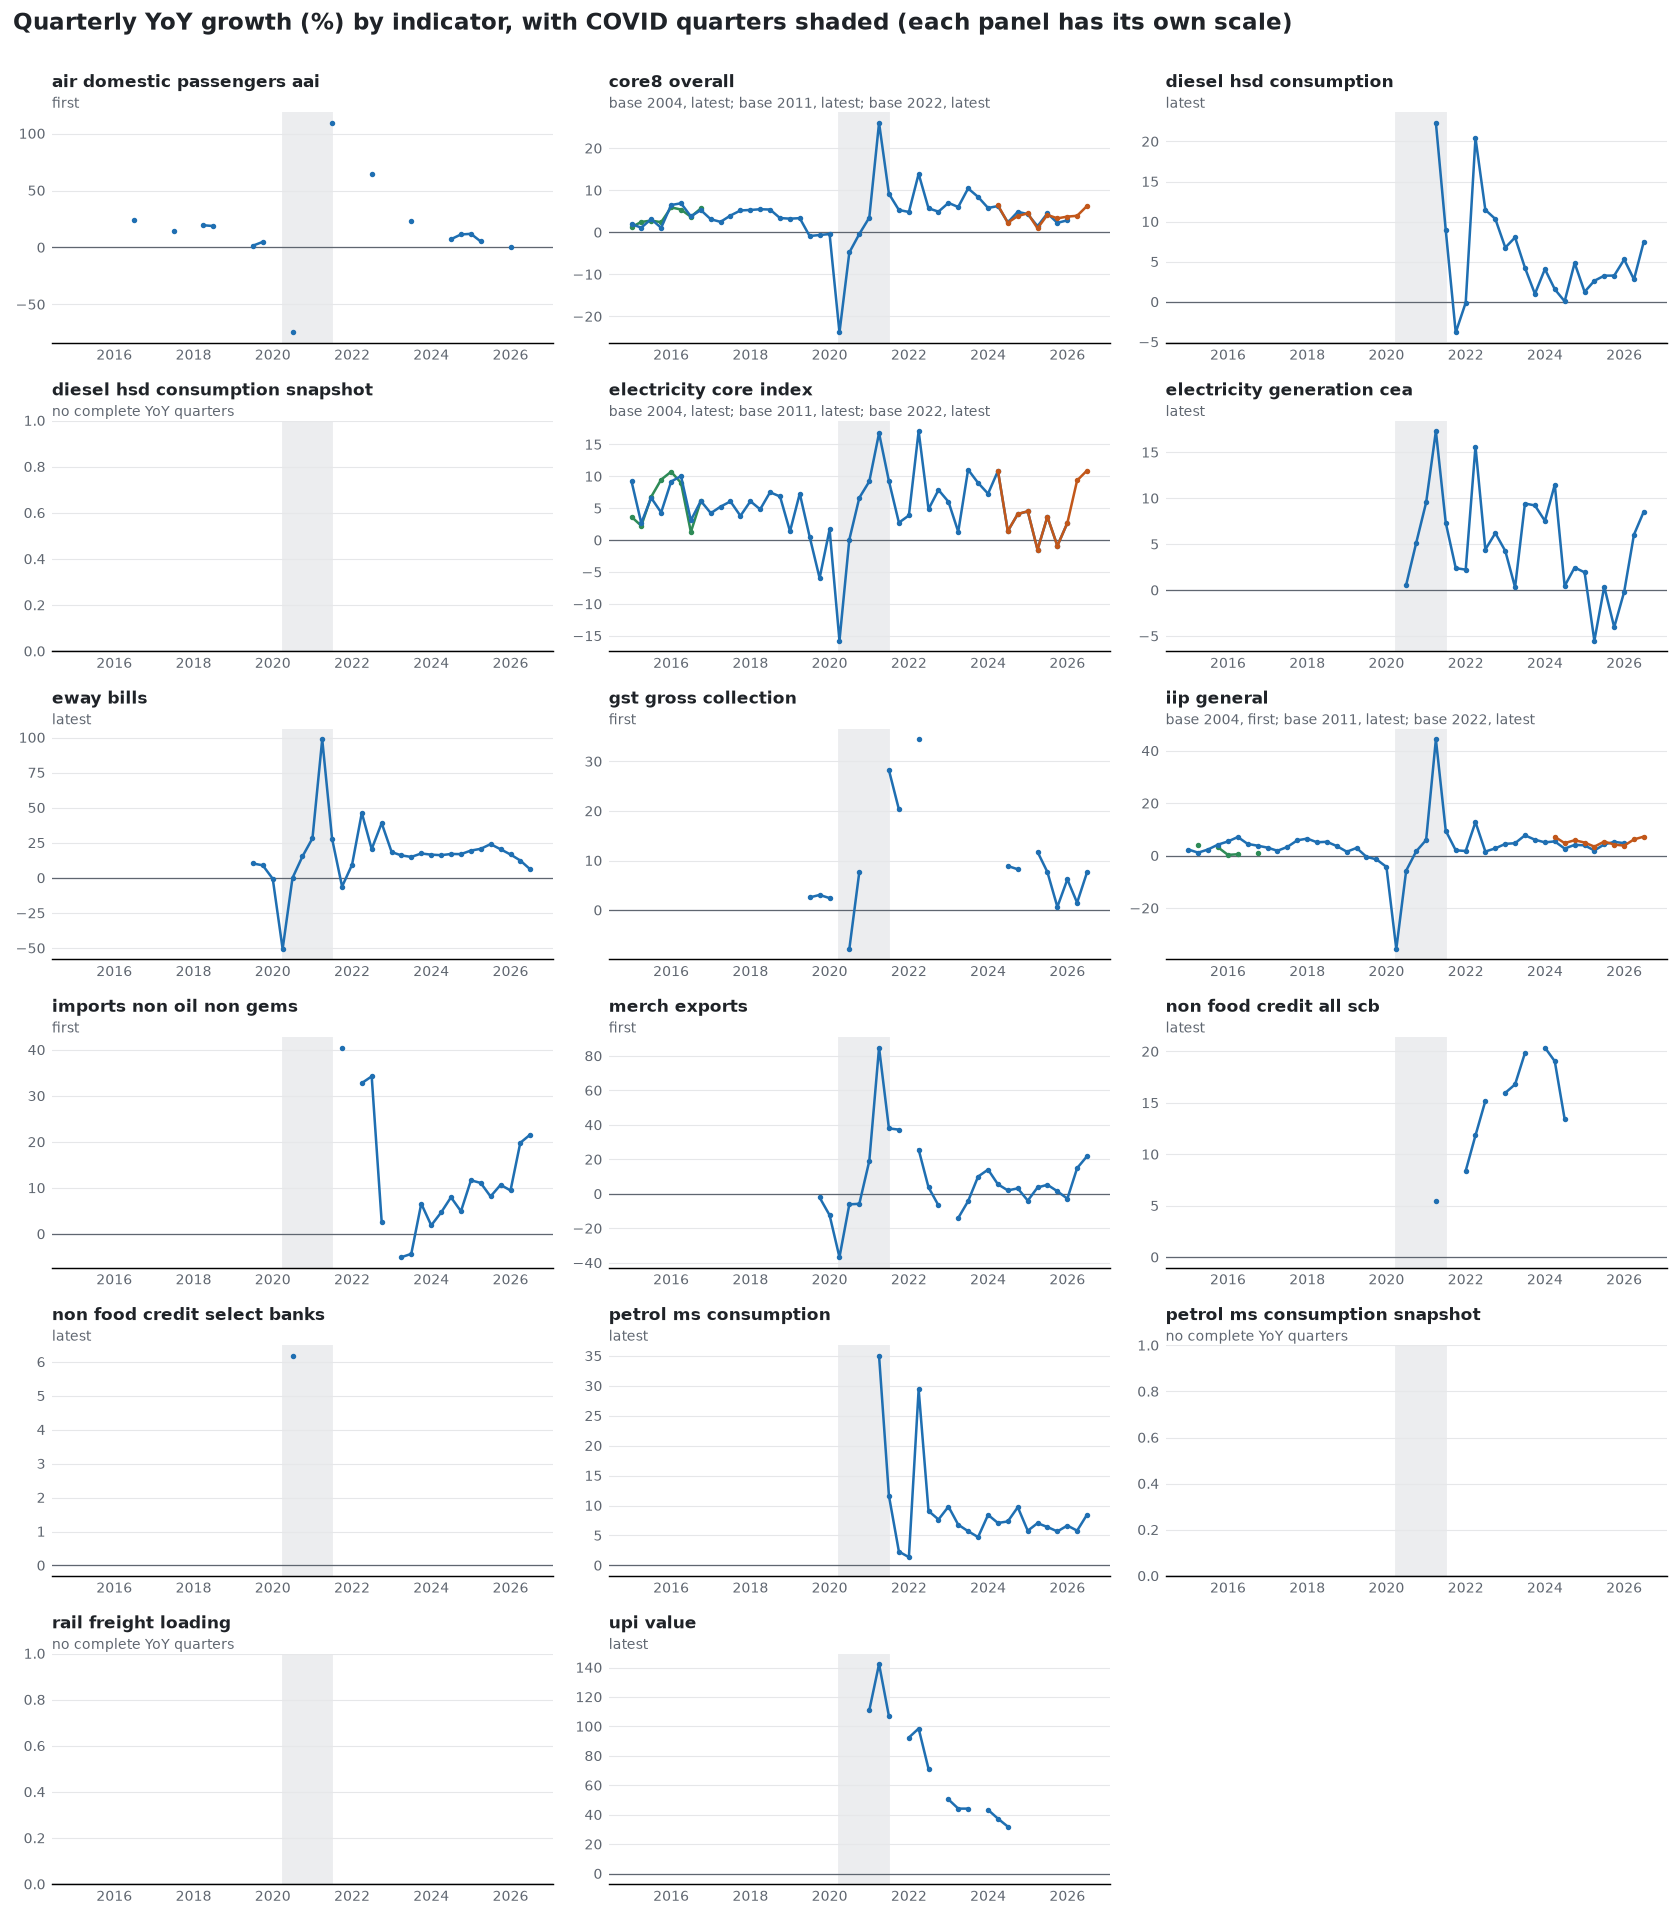

In [15]:
COLORS = {"": "#1F6FB2", "2004": "#2E8B57", "2011": "#1F6FB2", "2022": "#C2571A"}
INK, MUTED, GRID = "#1F2328", "#5F6670", "#E6E7E9"
quarterly["family"] = quarterly["indicator"].str.replace(r"_base\d{4}$", "", regex=True)
quarterly["base"] = quarterly["indicator"].str.extract(r"_base(\d{4})$")[0].fillna("")
families = sorted(quarterly["family"].unique())
cols = 3; rows_n = int(np.ceil(len(families) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(13, 2.5 * rows_n), dpi=130, sharex=True)
for ax, family in zip(axes.flat, families):
    ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2021-07-01"), color="#ECEDEF", zorder=0)
    ax.axhline(0, color=MUTED, lw=0.7)
    part = quarterly[(quarterly["family"] == family) & quarterly["yoy_pct"].notna()]
    labels = []
    for (base, vintage), g in part.groupby(["base", "vintage"]):
        # Prefer the latest vintage per base; show first prints only where there is no latest series.
        if vintage == "first" and ((part["base"] == base) & (part["vintage"] == "latest")).any():
            continue
        x = pd.PeriodIndex(g["quarter"], freq="Q").to_timestamp()
        full = pd.Series(g["yoy_pct"].values, index=x).reindex(pd.date_range(x.min(), x.max(), freq="QS"))
        ax.plot(full.index, full.values, color=COLORS[base], lw=1.4, marker="o", ms=2)
        labels.append((f"base {base}, " if base else "") + vintage)
    ax.set_title(family.replace("_", " "), loc="left", fontsize=9.5, color=INK, fontweight="bold", pad=14)
    ax.text(0, 1.02, "; ".join(labels) or "no complete YoY quarters", transform=ax.transAxes, fontsize=7.5, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0, labelsize=7.5, labelbottom=True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
for ax in axes.flat[len(families):]:
    ax.axis("off")
fig.suptitle("Quarterly YoY growth (%) by indicator, with COVID quarters shaded (each panel has its own scale)", x=0.01, ha="left", fontsize=12.5, color=INK, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(REPORTS / "indicators_quarterly_yoy.png", bbox_inches="tight", facecolor="white")
plt.show()

## 15. Complete quarters, 2017Q2 to 2025Q3

The window has 34 quarters. A quarter counts only if all three months are present in that series and vintage.

In [16]:
window = pd.period_range("2017Q2", "2025Q3", freq="Q").astype(str)
in_window = quarterly[quarterly["quarter"].isin(window)]
complete_table = (in_window[in_window["complete"]].pivot_table(index="indicator", columns="vintage", values="quarter", aggfunc="count")
                  .reindex(sorted(quarterly["indicator"].unique())).fillna(0).astype(int))
complete_table = complete_table.reindex(columns=["first", "latest"], fill_value=0)
complete_table["either_vintage"] = [in_window[(in_window["indicator"] == name) & in_window["complete"]]["quarter"].nunique() for name in complete_table.index]
complete_table.to_csv(PROCESSED / "indicators_complete_quarters_2017Q2_2025Q3.csv")
display(complete_table)

vintage,first,latest,either_vintage
indicator,,,
air_domestic_passengers_aai,23,0,23
core8_overall_base2004,0,0,0
core8_overall_base2011,32,34,34
core8_overall_base2022,0,10,10
diesel_hsd_consumption,0,22,22
diesel_hsd_consumption_snapshot,0,0,0
electricity_core_index_base2004,0,0,0
electricity_core_index_base2011,0,34,34
electricity_core_index_base2022,0,10,10


## Data gaps

The coverage table above has the counts, and section 15 has complete quarters for 2017Q2 to 2025Q3. This cell explains them. **Only core 8, IIP and the core electricity sub-index are complete across that window.**

### Sources and look-ahead risk

| Indicator | Source | Vintage | Look-ahead risk |
|---|---|---|---|
| IIP | MoSPI press notes (first), MoSPI API (latest) | First to Sep 2025 | Low to Sep 2025. **High after that: the 2022-23 base has revised data only** |
| Core 8 | OEA press releases (first), OEA XLSX (latest) | First and latest | Low. **High for 2022-23 base before 2026-06** |
| Diesel, petrol from Apr 2020 | PPAC data call | **Latest only** | **High** |
| Diesel, petrol to Mar 2020 | PPAC Snapshots via Wayback | 13 first, 11 latest (prior-year column of a later report) | Low to medium |
| Electricity (MU) | CEA via NPP: tentative = first, actual = latest | First and latest | Low. No release dates |
| Electricity (core sub-index) | OEA XLSX | **Latest only** | **High**, and it overlaps with core 8 |
| Rail freight from Aug 2020 | PIB releases | First | Low |
| Rail freight before Aug 2020 | Comparisons quoted in later PIB releases | **Latest** | **High** |
| Domestic air | **AAI, not DGCA** | First only | Low |
| Exports, imports | PIB releases | First only | Low |
| Non-food credit, UPI | RBI Bulletin via Wayback | Earliest bulletin found, if within four months | **Medium: may not be the true first print** |
| GST | PIB releases, GST portal XLSX | First | Low. Apr 2024 onward XLSX values have no release date, and may be slightly revised |
| E-way bills | GST portal XLSX | **Latest only** | **High** |

### Series breaks

- **Non-food credit changes coverage, so it is two series.** Bulletins to May 2021 cover select banks (about 90% of credit). From the June 2021 bulletin, the table is based on the Section-42 return, covering all scheduled commercial banks. In the months where both exist, the all-bank figure is about 12-13% higher (section 9).
- **This explains the 11-15% jumps seen earlier in 2020-04, 2021-01 and 2021-03.** They came from mixing the two series, and aren't real growth or a merger. Within each series, the largest monthly move is under 5%. No YoY crosses this break.
- **The all-bank series has a merger effect from July 2023.** RBI's note says data since 28 July 2023 include the merger of a non-bank with a bank. The largest move near it is 2.9%. It is flagged, not adjusted.
- **Earlier credit notes also exclude ING Vysya** after its April 2015 merger with Kotak Mahindra, and the select-bank share differs between notes (95%, then about 90%).
- **Credit changes unit.** Older bulletins report in ₹ billion. Those are converted to ₹ crore.
- **IIP has three bases** (2004-05, 2011-12, 2022-23), kept separate. First prints move from 2004-05 to 2011-12 in 2017. The 2011-12 series ends Mar 2026.
- **Core 8 has the same three bases.** The 2022-23 index **adds iron ore as a ninth sector, so its composition differs** as well as its base.
- **Three IIP notes state no base.** They were assigned 2011-12, like every other note from that period, and are marked `base inferred` in the provenance file.

### Missing history

- **Diesel, petrol before Apr 2020:** 24 of 75 months, from Snapshot reports only, and no complete quarter. These round to 0.1 million tonnes (about 1-2% for diesel, 4-5% for petrol), so they stay in separate `_snapshot` series. Against the exact series after Apr 2020, the diesel gap has a median of 0.013 and a maximum of 0.047 million tonnes. data.gov.in wasn't tried, because `.env` wasn't in the project folder.
- **Rail freight:** blocked after two attempts. PIB's listing from 2017 has no monthly loading releases before mid-2020, and the archived Railways statistics folder has none. Seven months (2019-04 to 2019-07, 2020-05 to 2020-07) come from comparisons quoted later. PIB's listing doesn't reach before 2017.
- **Non-food credit:** RBI's file host returns an HTML page to scripts, so tables come only from Wayback captures. Roughly half the issues from 2014 have one, and many early issues have none.
- **UPI:** the same Wayback limit, and no value before Nov 2019. NPCI returns 403.
- **Exports, imports:** nothing before Aug 2018 and Oct 2020 respectively, and a few blanks after.
- **Domestic air:** 32 missing months. 15 are a block at the start (all of 2014, plus Jan, Mar and Apr 2015). The other 17 are scattered: 2015: 1, 2016: 1, 2017: 2, 2019: 3, 2020: 2, 2021: 2, 2022: 1, 2023: 2, 2025: 2, 2026: 1. They weren't found under the file names tried, which doesn't prove AAI never published them.
- **GST:** Jul 2017 to Mar 2018 and scattered months later.
- **E-way bills:** starts Jul 2018, matching the official file.
- **Electricity (MU):** starts late 2017 for tentative figures and mid-2019 for actuals.
- **Core 8 first prints:** blank for 2014-03, 2015-07, 2016-05, 2016-09, 2016-12, 2017-01 to 2017-04, 2024-12 and 2026-09. The PDFs have no extractable index, and several are scanned images.
- **IIP first prints:** scattered blanks, and none after Sep 2025.
- **Not collected:** PMI, because no free official historical source was found.

### Definitions that differ from the request

- **Domestic air** is passengers handled at airports (AAI), not passengers carried by airlines (DGCA). The levels aren't comparable, and YoY may differ too.
- **Imports** are non-petroleum, non-gems & jewellery, as the ministry reports them. This is narrower than non-oil non-gold, because it also excludes silver and precious stones.
- **Electricity (MU)** is the CEA summary total: thermal, nuclear, hydro and Bhutan imports. It **excludes most renewables**, so it understates generation increasingly over time.
- **E-way bills** are within-state plus outgoing. Incoming bills are excluded to avoid double-counting.
- **Non-food credit** is a stock at a reporting Friday late in the month, so quarters use the average of the months.

### Release dates

- Dates come from several methods, listed per row in `indicators_provenance.csv`.
- **PDF creation dates** (older core notes, AAI) are a proxy for the release date, not an announced date.
- **RBI dates** come from the file name where it has one, and are the bulletin date, which is later than the first publication elsewhere. The lag of about 50 days overstates how late this data is available.
- **Rows with an implausible date are removed** from the first-print vintage, because they can't be shown to be first prints.
- **First-print YoY** compares two first prints a year apart, so it isn't always the growth rate published in the note.

### Parsing safeguards

- First prints are compared with the latest series where both exist, and none is more than 15% away.
- Snapshot figures outside a plausible range are rejected as misread columns.
- Rail, air, exports, imports and GST have no second source in this notebook, so wrong-sentence errors can't be fully ruled out there.
- **Reproducibility:** files are re-downloaded when absent. Wayback and PIB drop requests when busy, so both are retried, and the number of PIB pages retrieved is printed. Two runs from empty folders matched except for RBI bulletin tables, where Wayback refused a different file each time despite the retries (under 5 rows). A refusal can persist across reruns: the May 2021 credit table failed in two later runs, so the committed outputs use the copy from the first run, same URL. A fresh run may therefore show a few fewer credit or UPI rows, so check the PIB and RBI counts.
